# Directional Coupler — FDTD/EME Hybrid Simulation

```
    "in"  ___                                      ____  "through"
             \
              \__________________________________/        (coupling gap)
              /                                    \
    ___      /                                      \___  "cross"
   "isolated"

    |<- bend_length ->|<--- coupling_length --->|<- bend_length ->|
```

Three physically distinct features, but only **2 FDTD simulations + 1 EME
simulation total**:

    [input S-bend]  ->  [straight coupled pair]  ->  [output S-bend]
       FDTD (x2)               EME (x1)              reused, not resimulated

- The S-bends that carry the excited waveguide from a well-isolated access pitch
  down into the tight coupling gap (and back out again) are curved,
  non-adiabatic features — exactly what FDTD is for.
- The straight coupled-pair region is where the actual directional coupling
  happens: an eigenmode expansion over its 2 supermodes (even + odd) is both
  exact and far cheaper than FDTD here. Each individual arm is single-mode by
  design, so 2 modes fully capture the excited coupling physics.
- The output section is NEVER separately simulated. `DirectionalCoupler` has no
  left/right asymmetry (same bend_length, coupling_pitch, waveguide_offset,
  bend_type on both sides), so the output section is *exactly* the input
  section mirrored in x. By reciprocity, running the input section once per
  input arm ("in" and "isolated") gives *both* the input- and output-side
  transfer matrices — the "through"/"cross" matrices are just those results
  transposed (mode axes swapped), not resimulated.

Coupling-length sweep — the classic directional-coupler "beat length"
characterization — without any additional FDTD or EME simulations:

- The input/output FDTD sections' transfer matrices don't depend on
  coupling_length (the S-bend/access-waveguide geometry is defined relative to
  the coupling-region edges). They're solved exactly once each, using one
  reference `DirectionalCoupler` instance built at the *middle* of the length
  sweep.
- The EME body's mode profiles and effective indices depend only on the
  coupling cross-section (width/gap), not on how long the straight section is —
  so `EMESolver.solve_section_length_sweep()` computes the two supermodes once
  per wavelength and reuses them for every length in the sweep, each just a
  cheap diagonal phase-matrix evaluation. Total solver cost is the same as a
  single fixed coupling_length run regardless of sweeping 201 lengths instead
  of 1.

`HybridSolver` itself has no idea this is a directional coupler; it only knows
each solver implements `solve_section()` and combines the resulting per-section
modal transfer matrices by matrix-chain multiplication. The coupler-specific
geometry (S-bends, coupling region) lives entirely in `DirectionalCoupler`'s
`section_prisms`/`section_gds`/`width_at`/`center_at` methods.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

from beef import (
    DirectionalCoupler, EMESolver, FDTDSolver, HybridSolver, SMatrix, SOI_220, plot_hybrid_geometry,
)

In [ ]:
# Global simulation parameters
RESOLUTION = 40.0   # mesh resolution (pixels/um) — used by both the EME and FDTD sub-solvers
WL_MIN = 1.50       # wavelength sweep start (um)
WL_MAX = 1.60       # wavelength sweep end (um)
N_WL = 11           # number of wavelength points

# Coupling length used for the wavelength-domain ("hybrid_results") plot and the
# SMatrix. Set to a specific value (um) to pin it; leave as None to auto-pick the
# length in coupling_lengths (defined below) whose coupling ratio is closest to a
# 50:50 (3 dB) split.
PLOT_COUPLING_LENGTH = None   # um, or None for auto (50:50 split point)

In [ ]:
# Persistent on-disk simulation cache (see beef/cache/) — a solve_section()
# call whose config matches a prior cached run loads that result instead of
# re-simulating. Assumes this notebook runs from its own directory
# (examples/directional_coupler/notebooks/), matching directional_coupler_hybrid.py's save_dir.
save_dir = os.path.abspath(os.path.join("..", "..", "example_sim_cache"))

In [ ]:
# 1. Geometry — all device dimensions as variables (220 nm SOI).
#
#    coupling_lengths is the actual sweep; dc itself is built at the sweep's
#    middle value (bends/access-waveguide geometry don't depend on
#    coupling_length, so this single instance is equally valid as the
#    reference geometry for the FDTD sections at every length in the sweep).
coupling_lengths = np.linspace(0.0, 60.0, 201)   # um, the swept coupling length
L_mid = coupling_lengths[len(coupling_lengths) // 2]

dc = DirectionalCoupler(
    waveguide_width=0.45,    # single-mode strip width (um)
    gap=0.25,                # coupling-region edge-to-edge gap (um)
    coupling_length=L_mid,   # straight parallel interaction length (um) — sweep reference value
    bend_length=9.0,         # horizontal extent of each S-bend (um)
    waveguide_offset=3.0,    # far-end centre-to-centre port pitch (um)
    bend_type="euler",       # "euler" (cubic-Bezier S-bend) or "circular" (matched arcs)
    waveguide_height=0.22,   # Si layer thickness (um) — SOI_220
)
print(f"Directional coupler total length: {dc.total_length:.2f} um "
      f"(coupling pitch {dc.coupling_pitch:.3f} um, far pitch {dc.waveguide_offset:.2f} um)")
print(f"Coupling length sweep: {coupling_lengths[0]:.1f} - {coupling_lengths[-1]:.1f} um "
      f"({len(coupling_lengths)} pts, build reference length = {L_mid:.2f} um)")

Directional coupler total length: 48.00 um (coupling pitch 0.700 um, far pitch 3.00 um)
Coupling length sweep: 0.0 - 60.0 um (201 pts, build reference length = 30.00 um)


In [ ]:
# 2. Configure sub-solvers — one per section.
#
#    input section  : input access waveguide + input S-bend, ending exactly
#                      at the S-bend/coupling-region seam
#    body section   : propagates N_MODES supermodes through the full
#                      straight coupled-pair region (length = coupling_length)
#    output section : the mirror image of the input section, one instance
#                      per output port ("through" / "cross")
N_MODES = 6   # even + odd supermodes carried at the two body interfaces

_fdtd_common = dict(
    res=RESOLUTION,
    sim_width=6.0,        # >= waveguide_offset + margin, so both far-pitch arms sit inside PML clearance
    sim_height=1.5,
    dpml=0.5,
    source_margin=0.0,
    monitor_margin=0.25,
    three_d=True,       # full 3-D FDTD: real 220 nm Si core in oxide, PML on all six faces
    # A full-sim_width source/norm aperture at a true I/O port would reach past
    # the shared y=0 axis to the *other* arm (only waveguide_offset away), since
    # both arms are always physically present in a section - corrupting the
    # isolated single-arm excitation. half_domain_aperture confines the aperture
    # to the near half of the domain (from the symmetry axis to the near PML
    # edge) instead.
    half_domain_aperture=True,
    material_stack=SOI_220,
    decay_tol=1e-11,
)

# One FDTDSolver instance covers both the input and output sections — they're
# mirror images of the same physical structure, so there's no need for two
# separately-configured objects.
fdtd_solver = FDTDSolver(**_fdtd_common)
body_solver = EMESolver(
    num_modes=[N_MODES], num_cells=[1], lengths=[1.0],  # placeholder length; solve_section_length_sweep() sweeps its own
    oxide_width=6.0, oxide_height=1.5, res=RESOLUTION, material_stack=SOI_220,
    mode_solver="meep",  # matches FDTDSolver's own eigenmode basis in this hybrid chain
)

In [ ]:
# 3. Build HybridSolver — 3-section chain: FDTD bend | EME coupling | FDTD bend.
#    (Used below only for the geometry/section preview plots; the actual
#    numeric sweep bypasses HybridSolver.solve() — see step 5.)
half_body = dc.coupling_length / 2
half_total = dc.total_length / 2

boundaries = [
    -half_total,   # physical input port (access waveguide end)
    -half_body,    # input section <-> body section interface (S-bend/coupling-region seam)
    +half_body,    # body section <-> output section interface (S-bend/coupling-region seam)
    +half_total,   # physical output port (access waveguide end)
]
interface_modes = [N_MODES, N_MODES]

hybrid = HybridSolver(
    solvers=[fdtd_solver, body_solver, fdtd_solver],
    boundaries=boundaries,
    interface_modes=interface_modes,
)

# Interface-monitor override for the input-section FDTD runs: span the full
# non-PML domain — PML inner edge to PML inner edge — centered on the coupled
# pair's shared y=0 axis. Without this the monitor inherits its centre from
# center_at() sampled just inside the S-bend, i.e. the excited arm's
# +-coupling_pitch/2 centreline: the window then pokes into one PML, misses the
# last bit of domain on the other side, differs between the "in" and "isolated"
# runs, and sits shifted relative to the EME body's own y=0-centered supermode
# basis it is matrix-multiplied against.
_iface_mon = dict(monitor_center=0.0, monitor_size=fdtd_solver.sim_width)

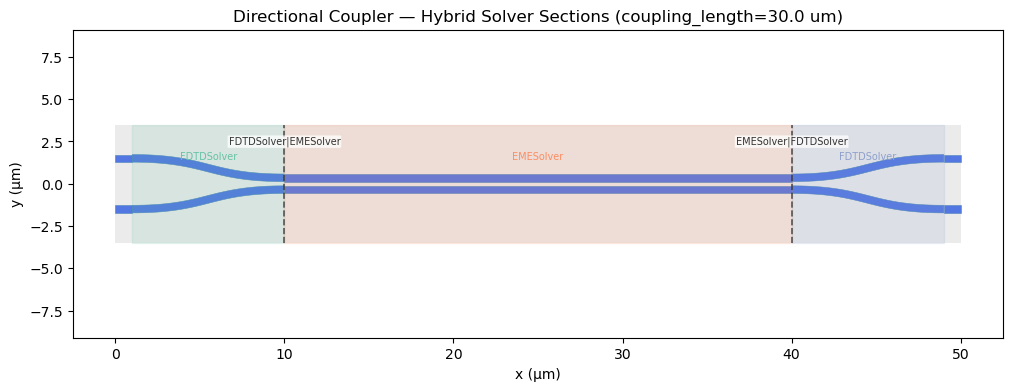

In [ ]:
# 4. Geometry plot — shows which solver covers which section, at dc's
#    (middle-of-sweep) coupling_length.
plot_hybrid_geometry(
    dc, solver=hybrid,
    in_modes=1, out_modes=1,
    title=f"Directional Coupler — Hybrid Solver Sections (coupling_length={L_mid:.1f} um)",
)
plt.show()

In [ ]:
# 5. Run the sweep — 2 FDTD solves (input section, once per input arm) plus one
#    EME mode-solve per wavelength, combined with the coupling_length-swept body
#    matrix via the same matrix-chain contraction HybridSolver.solve() uses
#    internally (broadcast over the extra length axis). The output section is
#    never separately simulated: M_in0/M_in1 double as the output-side transfer
#    matrices once transposed — "through" is the mirror of "in", "cross" of
#    "isolated".
wavelengths = np.linspace(WL_MIN, WL_MAX, N_WL)
print(f"\nWavelength sweep: {wavelengths[0]:.3f} - {wavelengths[-1]:.3f} um "
      f"({len(wavelengths)} pts, {N_MODES} interface modes)\n")

M_in0 = fdtd_solver.solve_section(
    dc, wavelengths, boundaries[0], boundaries[1],
    n_modes_in=1, n_modes_out=N_MODES,
    stub_left=fdtd_solver.waveguide_length, stub_right=0.0,
    input_idx=0, save_dir=save_dir, **_iface_mon,
)  # [n_wl, N_MODES, 1] — "in" arm -> body modes
M_in1 = fdtd_solver.solve_section(
    dc, wavelengths, boundaries[0], boundaries[1],
    n_modes_in=1, n_modes_out=N_MODES,
    stub_left=fdtd_solver.waveguide_length, stub_right=0.0,
    input_idx=1, save_dir=save_dir, **_iface_mon,
)  # [n_wl, N_MODES, 1] — "isolated" arm -> body modes

M_out_through = M_in0.transpose(0, 2, 1)  # [n_wl, 1, N_MODES] — mirror-symmetry reuse, not a new simulation
M_out_cross = M_in1.transpose(0, 2, 1)    # [n_wl, 1, N_MODES]

# The FDTD input/output sections end exactly at the S-bend/coupling-region seam
# (boundaries[1]/[2] above capture none of the straight interior), so the EME
# body models the full nominal coupling_length directly.
body_lengths = coupling_lengths
M_body = body_solver.solve_section_length_sweep(
    dc, wavelengths, boundaries[1], boundaries[2], body_lengths,
    n_modes_in=N_MODES, n_modes_out=N_MODES, save_dir=save_dir,
)  # [n_L, n_wl, N_MODES, N_MODES]

tmp = np.einsum("Lwij,wjk->Lwik", M_body, M_in0)                        # [n_L, n_wl, N_MODES, 1]
full_through = np.einsum("wij,Lwjk->Lwik", M_out_through, tmp)          # [n_L, n_wl, 1, 1]
full_cross = np.einsum("wij,Lwjk->Lwik", M_out_cross, tmp)              # [n_L, n_wl, 1, 1]

T_through_grid = np.abs(full_through[:, :, 0, 0]) ** 2   # [n_L, n_wl]
T_cross_grid = np.abs(full_cross[:, :, 0, 0]) ** 2        # [n_L, n_wl]
T_total_grid = T_through_grid + T_cross_grid


Wavelength sweep: 1.500 - 1.600 um (11 pts, 6 interface modes)

Using MPI version 4.1, 1 processes


In [ ]:
# 5b. Choose the coupling length used for the wavelength-domain plot/SMatrix.
#     PLOT_COUPLING_LENGTH pins it explicitly (snapped to the nearest sampled
#     length); left as None, auto-pick the shortest length whose mean-over-
#     wavelength cross/through ratio crosses 0.5 (the "3 dB coupler length").
if PLOT_COUPLING_LENGTH is not None:
    L_plot_idx = int(np.argmin(np.abs(coupling_lengths - PLOT_COUPLING_LENGTH)))
    print(f"Plot length: user-set {PLOT_COUPLING_LENGTH:.2f} um -> "
          f"nearest sampled length {coupling_lengths[L_plot_idx]:.2f} um")
else:
    ratio_mean = T_cross_grid.mean(axis=1) / np.clip(T_total_grid.mean(axis=1), 1e-20, None)
    sign_changes = np.flatnonzero(np.diff(np.sign(ratio_mean - 0.5)))
    if sign_changes.size:
        i = sign_changes[0]
        L_plot_idx = i if abs(ratio_mean[i] - 0.5) <= abs(ratio_mean[i + 1] - 0.5) else i + 1
    else:
        L_plot_idx = int(np.argmin(np.abs(ratio_mean - 0.5)))
    print(f"Plot length: auto-picked {coupling_lengths[L_plot_idx]:.2f} um "
          f"(50:50 split, ratio = {ratio_mean[L_plot_idx]:.3f})")
L_plot = coupling_lengths[L_plot_idx]

# Slice at the chosen coupling_length for the wavelength-domain view — keep the
# complex coefficients (not just power) for this slice so the saved SMatrix
# preserves phase.
coeff_through = full_through[L_plot_idx, :, 0, 0]
coeff_cross = full_cross[L_plot_idx, :, 0, 0]
T_through = T_through_grid[L_plot_idx]
T_cross = T_cross_grid[L_plot_idx]
T_total = T_total_grid[L_plot_idx]

wl_c = wavelengths[len(wavelengths) // 2]
idx = np.argmin(np.abs(wavelengths - wl_c))

smat = SMatrix(wavelengths=wavelengths)
smat.set(coeff_through, port="through")
smat.set(coeff_cross, port="cross")
smat.check_passive()  # sanity: total output power must not exceed 1 at any wavelength

Plot length: auto-picked 13.50 um (50:50 split, ratio = 0.505)


True

In [ ]:
# 6. Print summary
print(f"Results at coupling_length = {L_plot:.2f} um, wavelength = {wl_c:.3f} um:")
print(f"  Through output T = {T_through[idx]:.4f}  IL = {10*np.log10(max(T_through[idx],1e-20)):.2f} dB")
print(f"  Cross output   T = {T_cross[idx]:.4f}  IL = {10*np.log10(max(T_cross[idx],1e-20)):.2f} dB")
print(f"  Total          T = {T_total[idx]:.4f}  IL = {10*np.log10(max(T_total[idx],1e-20)):.2f} dB")
print(f"  Coupling ratio   = {T_cross[idx]/max(T_total[idx],1e-20):.3f}  "
      f"(0 = fully through, 1 = fully cross)")

Results at coupling_length = 13.50 um, wavelength = 1.550 um:
  Through output T = 0.5053  IL = -2.96 dB
  Cross output   T = 0.4919  IL = -3.08 dB
  Total          T = 0.9972  IL = -0.01 dB
  Coupling ratio   = 0.493  (0 = fully through, 1 = fully cross)


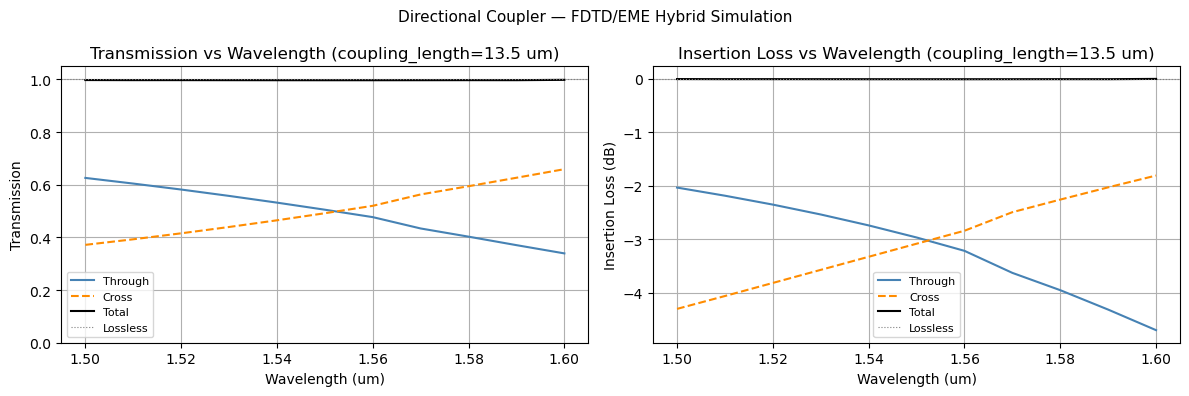

In [ ]:
# 7. Wavelength-domain plot, at the reference coupling_length
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(wavelengths, T_through, label="Through", color="steelblue")
ax.plot(wavelengths, T_cross,   label="Cross",   color="darkorange", linestyle="--")
ax.plot(wavelengths, T_total,   label="Total",   color="k", lw=1.5)
ax.axhline(1.0, color="gray", linestyle=":", lw=0.8, label="Lossless")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title(f"Transmission vs Wavelength (coupling_length={L_plot:.1f} um)")
ax.legend(fontsize=8)
ax.grid(True)
ax.set_ylim(0, 1.05)

ax = axes[1]
IL_through = 10 * np.log10(np.clip(T_through, 1e-20, None))
IL_cross   = 10 * np.log10(np.clip(T_cross,   1e-20, None))
IL_total   = 10 * np.log10(np.clip(T_total,   1e-20, None))
ax.plot(wavelengths, IL_through, label="Through", color="steelblue")
ax.plot(wavelengths, IL_cross,   label="Cross",   color="darkorange", linestyle="--")
ax.plot(wavelengths, IL_total,   label="Total",   color="k", lw=1.5)
ax.axhline(0.0, color="gray", linestyle=":", lw=0.8, label="Lossless")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Insertion Loss (dB)")
ax.set_title(f"Insertion Loss vs Wavelength (coupling_length={L_plot:.1f} um)")
ax.legend(fontsize=8)
ax.grid(True)

plt.suptitle("Directional Coupler — FDTD/EME Hybrid Simulation", fontsize=11)
plt.tight_layout()
plt.show()

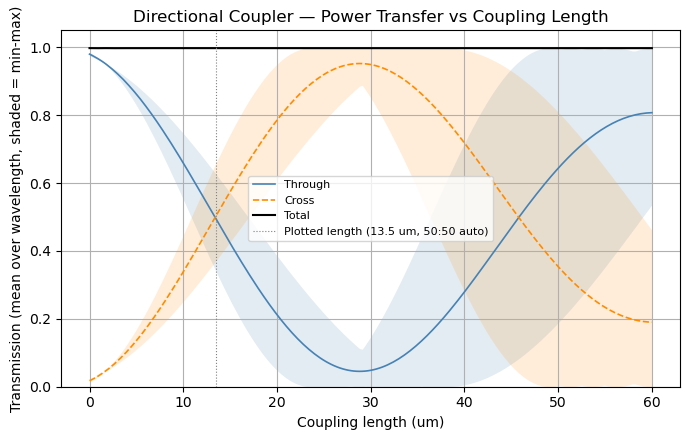

In [ ]:
# 8. Coupling-length sweep plot, mean/min/max across the wavelength sweep
#    (analytic, rides the same M_body length-swept solve from step 5)
fig, ax = plt.subplots(figsize=(7, 4.5))

for grid, label, color in [
    (T_through_grid, "Through", "steelblue"),
    (T_cross_grid,   "Cross",   "darkorange"),
    (T_total_grid,   "Total",   "k"),
]:
    mean, lo, hi = grid.mean(axis=1), grid.min(axis=1), grid.max(axis=1)
    ax.plot(coupling_lengths, mean, label=label, color=color,
            lw=1.5 if label == "Total" else 1.2,
            linestyle="--" if label == "Cross" else "-")
    ax.fill_between(coupling_lengths, lo, hi, color=color, alpha=0.15, lw=0)

_plot_len_note = "50:50 auto" if PLOT_COUPLING_LENGTH is None else "user-set"
ax.axvline(L_plot, color="gray", linestyle=":", lw=0.8,
           label=f"Plotted length ({L_plot:.1f} um, {_plot_len_note})")
ax.set_xlabel("Coupling length (um)")
ax.set_ylabel("Transmission (mean over wavelength, shaded = min-max)")
ax.set_title("Directional Coupler — Power Transfer vs Coupling Length")
ax.legend(fontsize=8)
ax.grid(True)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()